In [11]:
# TensorFlow
import tensorflow as tf

# Numerical operations
import numpy as np

# Visualization
import matplotlib.pyplot as plt

# Image generator
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Load saved model
from tensorflow.keras.models import load_model

# EfficientNet preprocessing
from tensorflow.keras.applications.efficientnet import preprocess_input

In [12]:
from tensorflow.keras.models import load_model

# Load model without optimizer
model = load_model(

    "../models/efficientnet_papsmear.keras",

    compile=False
)

In [13]:
# Define image size
IMG_SIZE = 224

# Batch size
BATCH_SIZE = 32

# Create image generator
datagen = ImageDataGenerator(

    # EfficientNet preprocessing
    preprocessing_function=preprocess_input,

    # Validation split
    validation_split=0.2
)

# Load ONLY validation dataset
val_data = datagen.flow_from_directory(

    # Dataset path
    "../dataset",

    # Resize images
    target_size=(IMG_SIZE, IMG_SIZE),

    # Batch size
    batch_size=BATCH_SIZE,

    # Multi-class labels
    class_mode='categorical',

    # Use validation subset only
    subset='validation',

    # Keep order fixed for evaluation
    shuffle=False
)

Found 1001 images belonging to 5 classes.


In [14]:
# Predict validation images
predictions = model.predict(val_data)

# Convert probabilities to class labels
predicted_classes = np.argmax(
    predictions,
    axis=1
)

# Retrieve actual labels
true_classes = val_data.classes

# Retrieve class names
class_labels = list(
    val_data.class_indices.keys()
)

32/32 ━━━━━━━━━━━━━━━━━━━━ 27s 763ms/step


In [15]:
# Display precision, recall and F1-score
print(classification_report(
    true_classes,
    predicted_classes,
    target_names=class_labels
))

                          precision    recall  f1-score   support

            Dyskeratotic       0.75      0.24      0.36       207
            Koilocytotic       0.56      0.27      0.36       212
             Metaplastic       0.31      0.90      0.46       212
               Parabasal       0.70      0.36      0.48       179
Superficial-Intermediate       0.50      0.35      0.41       191

                accuracy                           0.43      1001
               macro avg       0.57      0.42      0.42      1001
            weighted avg       0.56      0.43      0.42      1001



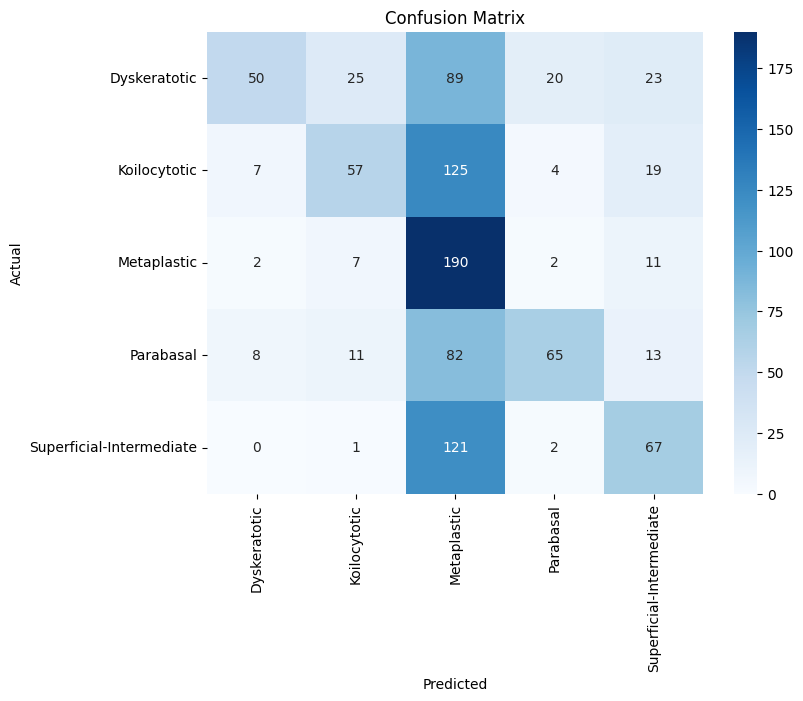

In [16]:
# Generate confusion matrix
cm = confusion_matrix(
    true_classes,
    predicted_classes
)

# Create figure
plt.figure(figsize=(8,6))

# Plot heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels
)

# Axis labels
plt.xlabel("Predicted")
plt.ylabel("Actual")

# Title
plt.title("Confusion Matrix")

# Show heatmap
plt.show()